# AI Price Optimizer — Training Notebook

Notebook ini mengerjakan seluruh alur yang diminta: **cleaning → feature engineering →
training → evaluasi**, memakai dataset dummy yang meniru struktur data hasil scraping
(`Product` di `packages/db/prisma/schema.prisma`).

Definisi problem AI & justifikasi algoritma ada di `01_PROBLEM_DEFINITION.md`.
Ringkasnya: **regresi kuantil** (Gradient Boosting, `loss="quantile"`) untuk memprediksi
*harga pasar wajar* (titik + rentang), bukan klasifikasi langsung "murah/mahal".

> Sesuai ketentuan lomba, notebook ini hanya mendemonstrasikan **core inference** dengan
> parameter statis. Tidak ada auto-tuning, bulk testing script, ataupun feedback-loop
> otomatis di sini.

In [1]:
import sys, time
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

from preprocessing import clean_raw_products, engineer_features, ALL_FEATURES, TARGET, build_feature_pipeline, get_output_feature_names
from train import train_quantile_models, predict_quantiles, save_models, STATIC_PARAMS, QUANTILES
from generate_dummy_data import generate_dummy_dataset

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (8, 4.5)

## 1. Dataset (dummy)

Data hasil scraping asli dari repo `price-optimizer` baru sedikit (masih tahap
development), jadi pipeline diuji dulu pakai **dataset dummy** yang bentuknya identik
dengan skema `Product` scraper: kategori, rating, total terjual, diskon, official store,
lokasi, dan tanggal scraping (untuk fitur musim). Distribusi harga dibuat berbeda tiap
kategori dan dipengaruhi rating, official store, kota, musim (Ramadan/Lebaran,
Harbolnas) — supaya pipeline benar-benar diuji menangkap pola yang relevan, bukan cuma
angka acak.

Begitu data scraping asli sudah cukup banyak (tabel `products` + `price_history` di
Postgres), fungsi `generate_dummy_dataset()` di sel ini tinggal diganti query ke DB;
skema kolom sudah disamakan dari awal supaya swap-nya minim perubahan.

In [2]:
dataset_path = "data/dummy_products.csv"
try:
    df_raw = pd.read_csv(dataset_path, parse_dates=["scraped_at"])
except FileNotFoundError:
    df_raw = generate_dummy_dataset()
    df_raw.to_csv(dataset_path, index=False)

print(df_raw.shape)
df_raw.head()

(6090, 14)


,external_id,marketplace,category,keyword_cluster,name,price,original_price,discount_percent,rating,total_reviews,total_sold,is_official_store,location,scraped_at
0,ker-05456,TOKOPEDIA,Kerajinan,Kerajinan:vas keramik,Vas Keramik varian 6,77500,77500,0,5.00,0,17.0,False,Makassar,2026-07-10
1,kec-05348,TOKOPEDIA,Kecantikan,Kecantikan:masker clay,Masker Clay varian 9,69500,69500,0,4.49,64,265.0,False,Bandung,2026-05-25
2,ele-02449,SHOPEE,Elektronik,Elektronik:charger usb-c,Charger Usb-C varian 6,7232500,9643500,25,4.41,97,1200.0,False,Solo,2025-11-02
3,kec-03909,TOKOPEDIA,Kecantikan,Kecantikan:masker clay,Masker Clay varian 1,51000,51000,0,4.87,32,233.0,False,Solo,2025-10-05
4,ele-01208,TOKOPEDIA,Elektronik,Elektronik:earphone tws,Earphone Tws varian 14,7370500,7370500,0,4.55,47,337.0,False,Solo,2026-05-15


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6090 entries, 0 to 6089
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   external_id        6090 non-null   str           
 1   marketplace        6090 non-null   str           
 2   category           6090 non-null   str           
 3   keyword_cluster    6090 non-null   str           
 4   name               6090 non-null   str           
 5   price              6090 non-null   int64         
 6   original_price     6090 non-null   int64         
 7   discount_percent   6090 non-null   int64         
 8   rating             6030 non-null   float64       
 9   total_reviews      6090 non-null   int64         
 10  total_sold         6029 non-null   float64       
 11  is_official_store  6090 non-null   bool          
 12  location           6090 non-null   str           
 13  scraped_at         6090 non-null   datetime64[us]
dtypes: bool(1), datetim

## 2. Data Cleaning

Langkah cleaning (implementasi di `src/preprocessing.py::clean_raw_products`):
- Buang duplikat exact (overlap cache scraping).
- Buang baris dengan harga tidak valid (harga adalah target, tidak boleh diimputasi).
- Impute `rating`/`total_sold` yang kosong dengan **median per kategori** (bukan median
  global, karena rentang wajar tiap kategori beda jauh — rating kosong di kategori
  Elektronik semestinya diisi median rating Elektronik, bukan median lintas kategori).
- Clip outlier harga ekstrem per kategori (IQR ×3) supaya tidak menarik kuantil, tanpa
  membuang listing yang sah.

In [4]:
df_clean = clean_raw_products(df_raw)
print("Missing values sisa:\n", df_clean[["price","rating","total_sold","total_reviews","discount_percent"]].isna().sum())

[cleaning] 6090 -> 5940 baris (150 dibuang/duplikat)
Missing values sisa:
 price               0
rating              0
total_sold          0
total_reviews       0
discount_percent    0
dtype: int64


## 3. Feature Engineering

Fitur yang dibangun (detail di `src/preprocessing.py::engineer_features`):

- **Konteks kompetitor** (`competitor_price_mean/median/std/min/max`, `competitor_cluster_size`):
  dihitung per `keyword_cluster` (kategori+kata kunci produk sejenis), *excluding*
  listing itu sendiri (tidak boleh bocor ke fiturnya sendiri). **Penting**: dihitung dari
  **sampel kecil** (4-12 listing lain, meniru jumlah "Produk Serupa" yang realistis
  tersedia saat inference di dashboard) — bukan dari seluruh ratusan listing di cluster.
  Kalau training memakai statistik populasi penuh (varians sangat kecil) sementara
  inference nanti cuma punya segelintir listing pembanding (varians jauh lebih besar),
  model akan melihat kombinasi fitur yang tidak pernah ada saat training dan
  berekstrapolasi liar. Mensimulasikan ukuran sampel kecil sejak training membuat
  distribusi fitur konsisten dengan kondisi nyata saat inference.
- **Musim** (`month`, `is_seasonal_month`): flag bulan Ramadan/Lebaran & Harbolnas.
- **Lokasi** (`city_tier`): kota tier-1 (Jakarta/Surabaya/Bandung) vs tier-2/3.

Fitur `price` (harga listing itu sendiri) **tidak pernah** dipakai sebagai input —
hanya sebagai target training.

In [5]:
df_feat = engineer_features(df_clean)
feature_preview_cols = ["category","rating","total_sold","competitor_price_mean",
                         "competitor_price_median","competitor_cluster_size",
                         "month","is_seasonal_month","city_tier","price"]
df_feat[feature_preview_cols].head()

,category,rating,total_sold,competitor_price_mean,competitor_price_median,competitor_cluster_size,month,is_seasonal_month,city_tier,price
0,Kerajinan,5.00,17.0,5.993750e+04,58750.0,8,7,0,2,77500
1,Kecantikan,4.49,265.0,6.218182e+04,63500.0,11,5,0,1,69500
2,Elektronik,4.41,1200.0,9.666750e+06,9966000.0,4,11,1,3,7232500
3,Kecantikan,4.87,233.0,6.308333e+04,63000.0,6,10,0,3,51000
4,Elektronik,4.55,337.0,7.444750e+06,7309000.0,8,5,0,3,7370500


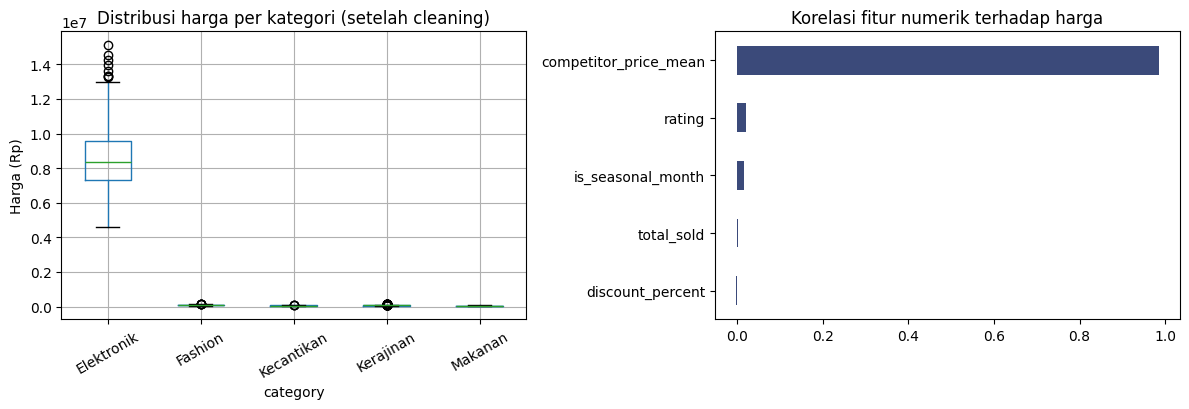

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df_feat.boxplot(column="price", by="category", ax=axes[0], rot=30)
axes[0].set_title("Distribusi harga per kategori (setelah cleaning)")
axes[0].set_ylabel("Harga (Rp)")
plt.suptitle("")

corr_cols = ["price","rating","total_sold","competitor_price_mean","discount_percent","is_seasonal_month"]
corr = df_feat[corr_cols].corr()["price"].drop("price").sort_values()
corr.plot(kind="barh", ax=axes[1], color="#3b4a7a")
axes[1].set_title("Korelasi fitur numerik terhadap harga")
plt.tight_layout()
plt.show()

## 4. Split Data (Train / Test)

Split 80/20, distratifikasi per kategori supaya proporsi tiap kategori UMKM
(Makanan/Fashion/Elektronik/Kecantikan/Kerajinan) terjaga di kedua set.

In [7]:
X = df_feat[ALL_FEATURES]  # "category" sudah termasuk di ALL_FEATURES
y = df_feat[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df_feat["category"]
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4752, 15)  Test: (1188, 15)


## 5. Training Model

Gradient Boosting Regression Trees dengan `loss="quantile"`, tiga model statis
(α = 0.1 / 0.5 / 0.9) untuk lower bound, median (estimasi utama), dan upper bound.
Hyperparameter **statis**, ditentukan lewat eksplorasi manual singkat, bukan
`GridSearchCV`/auto-tuning otomatis (sesuai ketentuan lomba).

In [8]:
print("Hyperparameter statis:", STATIC_PARAMS)
t0 = time.time()
models = train_quantile_models(X_train, y_train)
print(f"Total waktu training: {time.time()-t0:.1f}s")

Hyperparameter statis: {'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.8, 'min_samples_leaf': 15, 'random_state': 42}


[train] model 'lower' (alpha=0.1) selesai dilatih.


[train] model 'median' (alpha=0.5) selesai dilatih.


[train] model 'upper' (alpha=0.9) selesai dilatih.
Total waktu training: 7.0s


## 6. Evaluasi Model

Metrik yang dipakai:
- **MAE / RMSE / MAPE** untuk model median (titik estimasi "Harga Rata-rata Pasar").
- **Pinball loss** untuk tiap kuantil (metrik standar utk evaluasi quantile regression).
- **Coverage**: persentase data test yang harga aktualnya benar-benar jatuh di dalam
  rentang [lower, upper] yang diprediksi — idealnya mendekati 80% (karena rentang 0.1–0.9).

In [9]:
def pinball_loss(y_true, y_pred, alpha):
    diff = y_true - y_pred
    return np.mean(np.maximum(alpha * diff, (alpha - 1) * diff))

preds_test = predict_quantiles(models, X_test)

mae = mean_absolute_error(y_test, preds_test["median"])
rmse = mean_squared_error(y_test, preds_test["median"]) ** 0.5
mape = mean_absolute_percentage_error(y_test, preds_test["median"]) * 100

coverage = np.mean((y_test.values >= preds_test["lower"]) & (y_test.values <= preds_test["upper"])) * 100
avg_interval_width_pct = np.mean((preds_test["upper"] - preds_test["lower"]) / preds_test["median"]) * 100

print("=== Evaluasi model median (harga pasar wajar) ===")
print(f"MAE   : Rp {mae:,.0f}")
print(f"RMSE  : Rp {rmse:,.0f}")
print(f"MAPE  : {mape:.2f}%")
print()
print("=== Evaluasi rentang (quantile 0.1 - 0.9) ===")
print(f"Coverage aktual dlm rentang : {coverage:.1f}%  (target ~80%)")
print(f"Rata-rata lebar rentang     : {avg_interval_width_pct:.1f}% dari harga median")
print()
print("=== Pinball loss per kuantil ===")
for name, alpha in QUANTILES.items():
    pl = pinball_loss(y_test.values, preds_test[name], alpha)
    print(f"  {name:7s} (alpha={alpha}): {pl:,.0f}")

=== Evaluasi model median (harga pasar wajar) ===
MAE   : Rp 185,664
RMSE  : Rp 534,503
MAPE  : 10.90%

=== Evaluasi rentang (quantile 0.1 - 0.9) ===
Coverage aktual dlm rentang : 77.8%  (target ~80%)
Rata-rata lebar rentang     : 34.0% dari harga median

=== Pinball loss per kuantil ===
  lower   (alpha=0.1): 43,789
  median  (alpha=0.5): 92,832
  upper   (alpha=0.9): 48,475


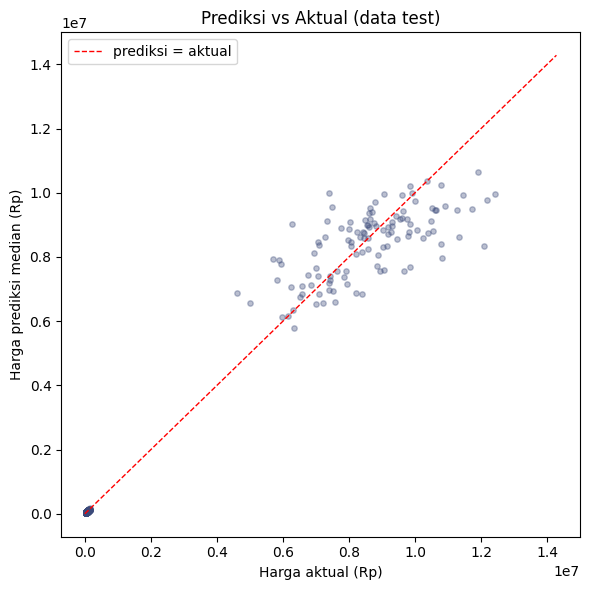

In [10]:
fig, ax = plt.subplots(figsize=(6,6))
sample = np.random.default_rng(0).choice(len(y_test), size=min(600, len(y_test)), replace=False)
ax.scatter(y_test.values[sample], preds_test["median"][sample], alpha=0.35, s=15, color="#3b4a7a")
lims = [0, max(y_test.max(), preds_test["median"].max())]
ax.plot(lims, lims, "r--", linewidth=1, label="prediksi = aktual")
ax.set_xlabel("Harga aktual (Rp)")
ax.set_ylabel("Harga prediksi median (Rp)")
ax.set_title("Prediksi vs Aktual (data test)")
ax.legend()
plt.tight_layout()
plt.show()

### Feature Importance ("Faktor yang Mempengaruhi")

Diambil langsung dari `feature_importances_` model median (native, tanpa SHAP/LIME
tambahan), lalu dikelompokkan ke kategori yang tampil di dashboard.

Harga kompetitor                              86.1
Lainnya (kategori, lokasi, official store)     7.5
Musim / momen                                  3.4
Rating & ulasan                                2.1
Tren penjualan                                 0.8
dtype: float64


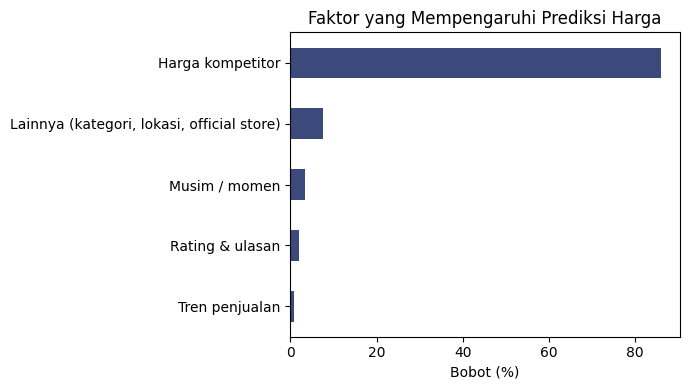

In [11]:
median_model = models["median"]
ct = median_model.named_steps["preprocess"]
gbr = median_model.named_steps["model"]
feature_names = get_output_feature_names(ct)
importances = pd.Series(gbr.feature_importances_, index=feature_names)

GROUPS = {
    "Harga kompetitor": ["competitor_price_mean","competitor_price_median","competitor_price_std",
                          "competitor_price_min","competitor_price_max"],
    "Rating & ulasan": ["rating","total_reviews"],
    "Tren penjualan": ["total_sold","competitor_cluster_size","discount_percent"],
    "Musim / momen": ["month","is_seasonal_month"],
}
grouped = {}
used = set()
for g, cols in GROUPS.items():
    grouped[g] = importances[cols].sum()
    used.update(cols)
other_cols = [c for c in importances.index if c not in used]
grouped["Lainnya (kategori, lokasi, official store)"] = importances[other_cols].sum()

grouped_series = pd.Series(grouped).sort_values(ascending=False)
grouped_pct = (grouped_series / grouped_series.sum() * 100).round(1)
print(grouped_pct)

fig, ax = plt.subplots(figsize=(7,4))
grouped_pct.sort_values().plot(kind="barh", ax=ax, color="#3b4a7a")
ax.set_xlabel("Bobot (%)")
ax.set_title("Faktor yang Mempengaruhi Prediksi Harga")
plt.tight_layout()
plt.show()

## 7. Simpan Model (artefak statis untuk inference)

Model disimpan sebagai satu file `.joblib` berisi 3 pipeline (lower/median/upper) +
metadata hyperparameter. Inilah artefak statis yang dipakai `src/inference.py` saat
demo — tidak ada retraining/tuning saat runtime.

In [12]:
save_models(models, "models/price_optimizer_models.joblib")

[save] model tersimpan di models/price_optimizer_models.joblib


## 8. Demo Inference

Simulasikan kasus di dashboard: **"Laptop ASUS Vivobook 14"**, dijual UMKM seharga
Rp8.200.000. Kita hitung fitur produk ini (kategori Elektronik, rating, total terjual,
konteks kompetitor "laptop asus vivobook" saat ini, bulan berjalan) — TANPA menyertakan
harga jual UMKM sebagai input — lalu model memprediksi rentang harga wajar dan
dibandingkan dengan harga jual UMKM.

Logika lengkap (confidence, status, rekomendasi teks) ada di `src/inference.py`,
di sini dipanggil langsung sebagai demonstrasi end-to-end.

In [13]:
from inference import analyze_price

competitor_snapshot = [8_150_000, 8_400_000, 8_550_000, 7_950_000, 8_050_000]

result = analyze_price(
    product_name="Laptop ASUS Vivobook 14",
    category="Elektronik",
    user_price=8_200_000,
    rating=4.8,
    total_reviews=210,
    total_sold=340,
    discount_percent=0,
    is_official_store=True,
    location="Jakarta",
    competitor_prices=competitor_snapshot,
    scraped_month=8,
)
import json
print(json.dumps(result, indent=2, ensure_ascii=False))

{
  "product_name": "Laptop ASUS Vivobook 14",
  "category": "Elektronik",
  "harga_toko_kamu": 8200000,
  "harga_rata_rata_pasar": 8778788,
  "rentang_harga_wajar": {
    "min": 6999400,
    "max": 9970088
  },
  "confidence_percent": 73.0,
  "status": "Wajar",
  "rekomendasi": "Harga kamu berada di rentang wajar pasar (Rp6,999,400 - Rp9,970,088). Posisi ini kompetitif — pertahankan, dan pantau terus pergerakan kompetitor.",
  "faktor_yang_mempengaruhi": {
    "Harga kompetitor": 86.1,
    "Rating & ulasan": 2.1,
    "Tren penjualan": 0.8,
    "Musim / momen": 3.4,
    "Lainnya": 7.5
  }
}


## 9. Ringkasan

- **Problem AI**: regresi kuantil untuk memprediksi rentang harga pasar wajar
  (bukan klasifikasi langsung murah/mahal).
- **Algoritma**: Gradient Boosting quantile regression (α 0.1/0.5/0.9), hyperparameter
  statis.
- **Pipeline**: cleaning → feature engineering (konteks kompetitor leave-one-out, musim,
  lokasi) → training → evaluasi (MAE/RMSE/MAPE, pinball loss, coverage interval).
- **Hasil di dataset dummy**: lihat metrik di Bagian 6 (angka aktual dari run notebook
  ini, bukan estimasi manual).
- **Langkah lanjut**: ganti `generate_dummy_dataset()` dengan query ke tabel `products`
  (Postgres, hasil scraping asli) begitu volume datanya cukup; skema kolom sudah
  disamakan dari awal.